# Goods receipts — fréquence des réceptions et attentes qualité


# 0. Bibliothèques


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import binom, fisher_exact
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import DBSCAN
from itertools import combinations
from collections import Counter

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/data_dictionary.csv').exists()), None)
assert ROOT is not None, 'Lancer le notebook depuis le dépôt.'
plt.rcParams.update({'figure.figsize':(10,4),'axes.grid':True,'grid.alpha':.2})


# 1. Charger les données


In [2]:
raw = pd.read_csv(ROOT / 'data/logistics/goods_receipts.csv')
df = pd.read_csv(ROOT / 'data/logistics/cleaned/goods_receipts_cleaned.csv')
print('Brut :', raw.shape, '| Nettoyé :', df.shape)


Brut : (612, 12) | Nettoyé : (610, 12)


In [3]:
print("Dimensions :",df.shape)
display(df.head(5))
print("Valeurs manquantes :")
display(df.isna().sum().to_frame("manquants"))
print("Doublons :",df.duplicated().sum())


Dimensions : (610, 12)
Valeurs manquantes :
Doublons : 0


,receipt_number,purchase_order_number,purchase_order_line,receipt_date,receiving_facility_code,supplier_partner_code,received_quantity,received_unit,batch_reference,inspection_status,storage_location_code,receipt_status
0,RCV-2014-00001,PO-2014-00001,1,2014-07-08,FCL-1007,BP-30078,73.0,case,B-2014-44545,held,BIN-35,quality_hold
1,RCV-2015-00002,PO-2015-00001,1,2015-02-02,FCL-1010,BP-30068,0.9,service,B-2015-58495,accepted,BIN-36,posted
2,RCV-2015-00003,PO-2015-00002,1,2015-02-28,FCL-1030,BP-30066,1.0,service,B-2015-48474,held,BIN-17,quality_hold
3,RCV-2015-00004,PO-2015-00003,1,2015-03-02,FCL-1010,BP-30080,3.0,pack,B-2015-71913,accepted,BIN-16,posted
4,RCV-2015-00005,PO-2015-00004,1,2015-02-21,FCL-1022,BP-30021,1.0,grant,B-2015-31154,accepted,BIN-42,posted


,manquants
receipt_number,0
purchase_order_number,0
purchase_order_line,0
receipt_date,0
receiving_facility_code,0
supplier_partner_code,0
received_quantity,0
received_unit,0
batch_reference,0
inspection_status,4


# 2. Explorer les réceptions


### Contrôler les statuts et dates


In [4]:
df["receipt_date"] = pd.to_datetime(df.receipt_date, errors="raise")
df["received_quantity"] = pd.to_numeric(df.received_quantity, errors="raise")
assert df.receipt_date.notna().all() and df.received_quantity.gt(0).all()
assert df.receipt_status.notna().all()
display(df.receipt_status.value_counts(dropna=False))
display(pd.crosstab(df.inspection_status.fillna("[non renseigné]"), df.receipt_status))
df["quality_hold"] = df.receipt_status.eq("quality_hold")
df["month"] = df.receipt_date.dt.to_period("M")
df["quarter"] = df.receipt_date.dt.to_period("Q")
global_rate = df.quality_hold.mean()
print("Période :", df.receipt_date.min().date(), "→", df.receipt_date.max().date())
print(f"Attentes qualité : {df.quality_hold.sum()} / {len(df)} = {global_rate:.2%}")


Période : 2014-07-08 → 2025-06-30
Attentes qualité : 34 / 610 = 5.57%


receipt_status
posted          576
quality_hold     34

receipt_status,posted,quality_hold
inspection_status,,
[non renseigné],4,0
accepted,505,0
conditional,67,0
held,0,34


### Volumes par établissement


### Calculer les intervalles de Wilson


In [5]:
def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    rate = k / n
    den = 1 + z * z / n
    center = (rate + z * z / (2 * n)) / den
    half = z * np.sqrt(rate * (1 - rate) / n + z * z / (4 * n * n)) / den
    # Les bornes exactes k=0/k=n évitent les erreurs d'arrondi à 1e-17.
    low = np.where(k == 0, 0.0, np.clip(center - half, 0, 1))
    high = np.where(k == n, 1.0, np.clip(center + half, 0, 1))
    return low, high


,n,held,rate,low,high
receiving_facility_code,,,,,
FCL-1011,133,5,0.037594,0.016163,0.084988
FCL-1007,76,4,0.052632,0.020655,0.127659
FCL-1010,61,5,0.081967,0.035519,0.177949
FCL-1019,54,3,0.055556,0.019073,0.151075
FCL-1030,37,5,0.135135,0.059132,0.279777
FCL-1020,33,1,0.030303,0.005369,0.153191
FCL-1015,23,2,0.086957,0.024179,0.267964
FCL-1016,23,1,0.043478,0.007716,0.209916
FCL-1029,20,1,0.050000,0.008881,0.236136


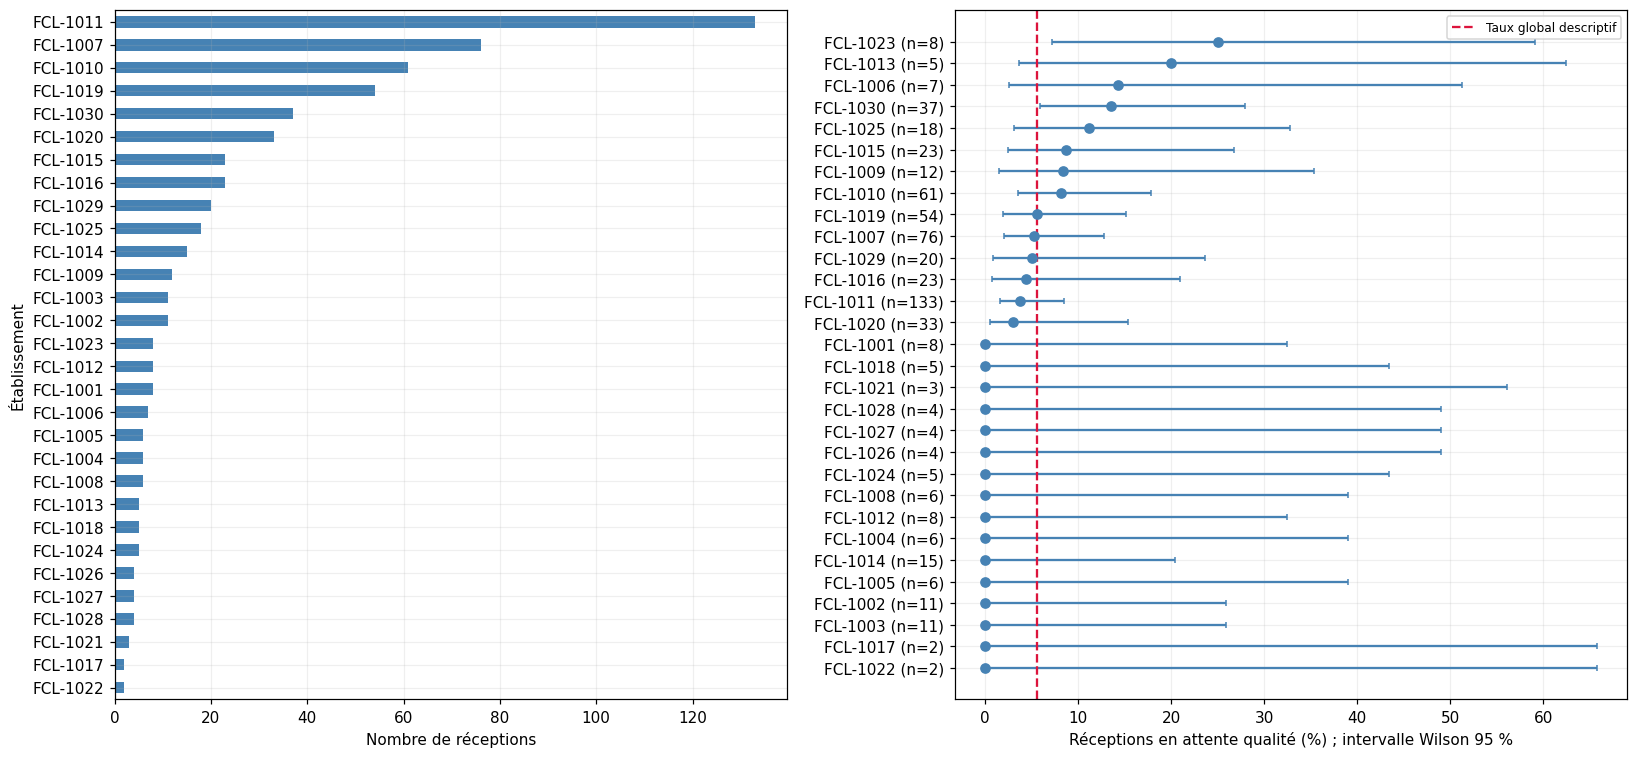

In [6]:
facility = df.groupby("receiving_facility_code").agg(
    n=("receipt_number", "size"), held=("quality_hold", "sum")
)
facility["rate"] = facility.held / facility.n
facility["low"], facility["high"] = wilson(facility.held, facility.n)
facility = facility.sort_values("n", ascending=False)
display(facility)
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
facility.n.sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_xlabel("Nombre de réceptions")
axes[0].set_ylabel("Établissement")
ordered = facility.sort_values("rate")
pos = np.arange(len(ordered))
axes[1].errorbar(
    100 * ordered.rate,
    pos,
    xerr=np.vstack(
        [100 * (ordered.rate - ordered.low), 100 * (ordered.high - ordered.rate)]
    ),
    fmt="o",
    capsize=2,
    color="steelblue",
)
axes[1].set_yticks(pos, [f"{idx} (n={n})" for idx, n in zip(ordered.index, ordered.n)])
axes[1].axvline(global_rate * 100, c="crimson", ls="--", label="Taux global descriptif")
axes[1].set_xlabel("Réceptions en attente qualité (%) ; intervalle Wilson 95 %")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


In [7]:
display(
    Markdown(
        "**Lecture :** les intervalles larges exposent l'incertitude des petits effectifs. La ligne globale est un repère ; le test ci-dessous compare chaque établissement aux autres, sans l'inclure dans sa propre référence."
    )
)


**Lecture :** les intervalles larges exposent l'incertitude des petits effectifs. La ligne globale est un repère ; le test ci-dessous compare chaque établissement aux autres, sans l'inclure dans sa propre référence.

### Évolution mensuelle et trimestrielle


In [8]:
months = pd.period_range(df.month.min(), df.month.max(), freq="M")
monthly = (
    df.groupby("month")
    .agg(n=("receipt_number", "size"), held=("quality_hold", "sum"))
    .reindex(months, fill_value=0)
)
quarters = pd.period_range(df.quarter.min(), df.quarter.max(), freq="Q")
quarterly = (
    df.groupby("quarter")
    .agg(n=("receipt_number", "size"), held=("quality_hold", "sum"))
    .reindex(quarters, fill_value=0)
)
quarterly["rate"] = quarterly.held / quarterly.n.replace(0, np.nan)


### ACF et STL : activité mensuelle enregistrée


Période analysée : 132 mois, dont 16 à zéro


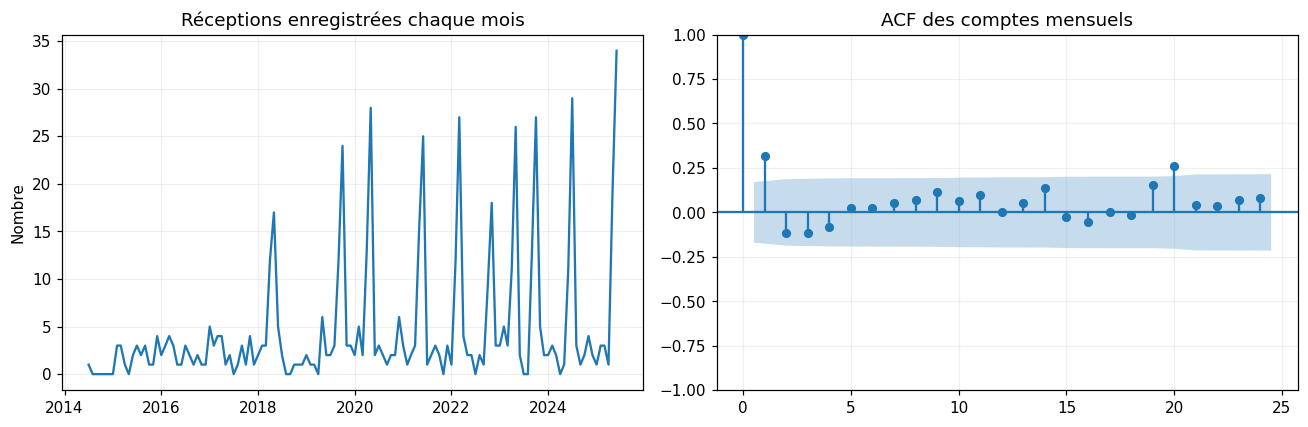

In [9]:
# Le total mensuel inclut les mois sans événement observé dans le fichier.
serie_receptions = monthly.n.copy()
serie_receptions.index = serie_receptions.index.to_timestamp()
print("Période analysée :", len(serie_receptions), "mois, dont", int(serie_receptions.eq(0).sum()), "à zéro")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(serie_receptions.index, serie_receptions.values)
axes[0].set(title="Réceptions enregistrées chaque mois", ylabel="Nombre")
plot_acf(serie_receptions, lags=24, ax=axes[1], title="ACF des comptes mensuels")
plt.tight_layout();plt.show()


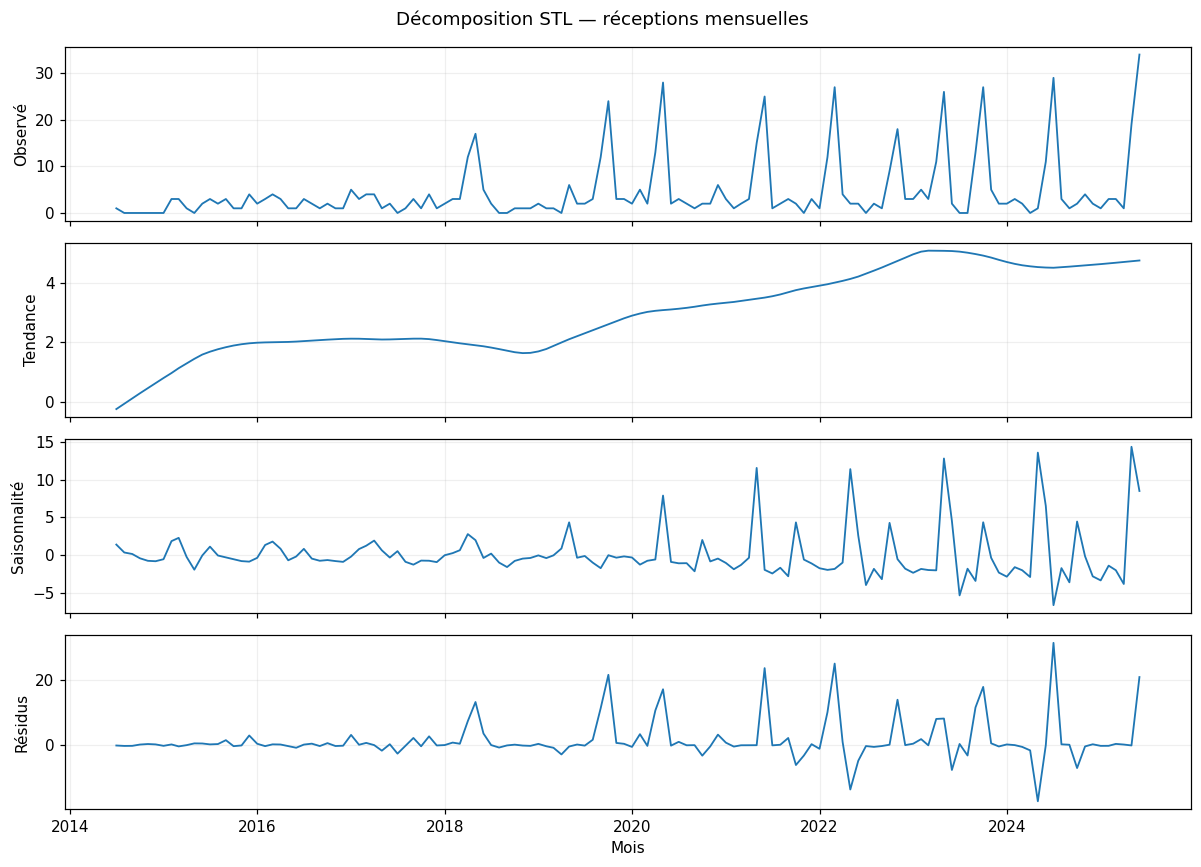

In [10]:
# STL décrit les fluctuations de l'activité ; elle ne valide pas l'hypothèse de couverture complète.
assert len(serie_receptions) >= 24
stl_receptions = STL(serie_receptions, period=12, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, values, titre in zip(axes,
        [serie_receptions, stl_receptions.trend, stl_receptions.seasonal, stl_receptions.resid],
        ["Observé", "Tendance", "Saisonnalité", "Résidus"]):
    ax.plot(serie_receptions.index, values, linewidth=1.2)
    ax.set_ylabel(titre)
axes[-1].set_xlabel("Mois")
fig.suptitle("Décomposition STL — réceptions mensuelles")
plt.tight_layout();plt.show()


In [11]:
mois_stl = pd.DataFrame({"receptions": serie_receptions,
                         "residu_stl": stl_receptions.resid})
mois_stl["ecart_absolu"] = mois_stl.residu_stl.abs()
display(mois_stl.nlargest(5, "ecart_absolu")[["receptions", "residu_stl"]].round(2))


,receptions,residu_stl
2024-07-01,29,31.18
2022-03-01,27,24.86
2021-06-01,25,23.48
2019-10-01,24,21.43
2025-06-01,34,20.74


**Lecture :** l’ACF mesure la répétition des comptes d’un mois à l’autre, et la STL sépare tendance, cycle annuel et variations restantes. Ici, les mois sans réception sont notés zéro **dans l’extraction**, sans preuve que l’activité était réellement nulle. Ces graphiques sont donc exploratoires ; les résidus STL ne constituent pas une nouvelle liste d’anomalies confirmées.


,n,held,rate,low,high
2022Q3,3,0,0.000000,0.000000,0.561506
2022Q4,30,2,0.066667,0.018477,0.213238
2023Q1,11,0,0.000000,0.000000,0.258840
2023Q2,39,4,0.102564,0.040613,0.235792
2023Q3,13,1,0.076923,0.013710,0.333145
2023Q4,34,3,0.088235,0.030465,0.229608
2024Q1,7,1,0.142857,0.025679,0.513135
2024Q2,12,0,0.000000,0.000000,0.242501
2024Q3,33,2,0.060606,0.016781,0.196066
2024Q4,8,0,0.000000,0.000000,0.324416


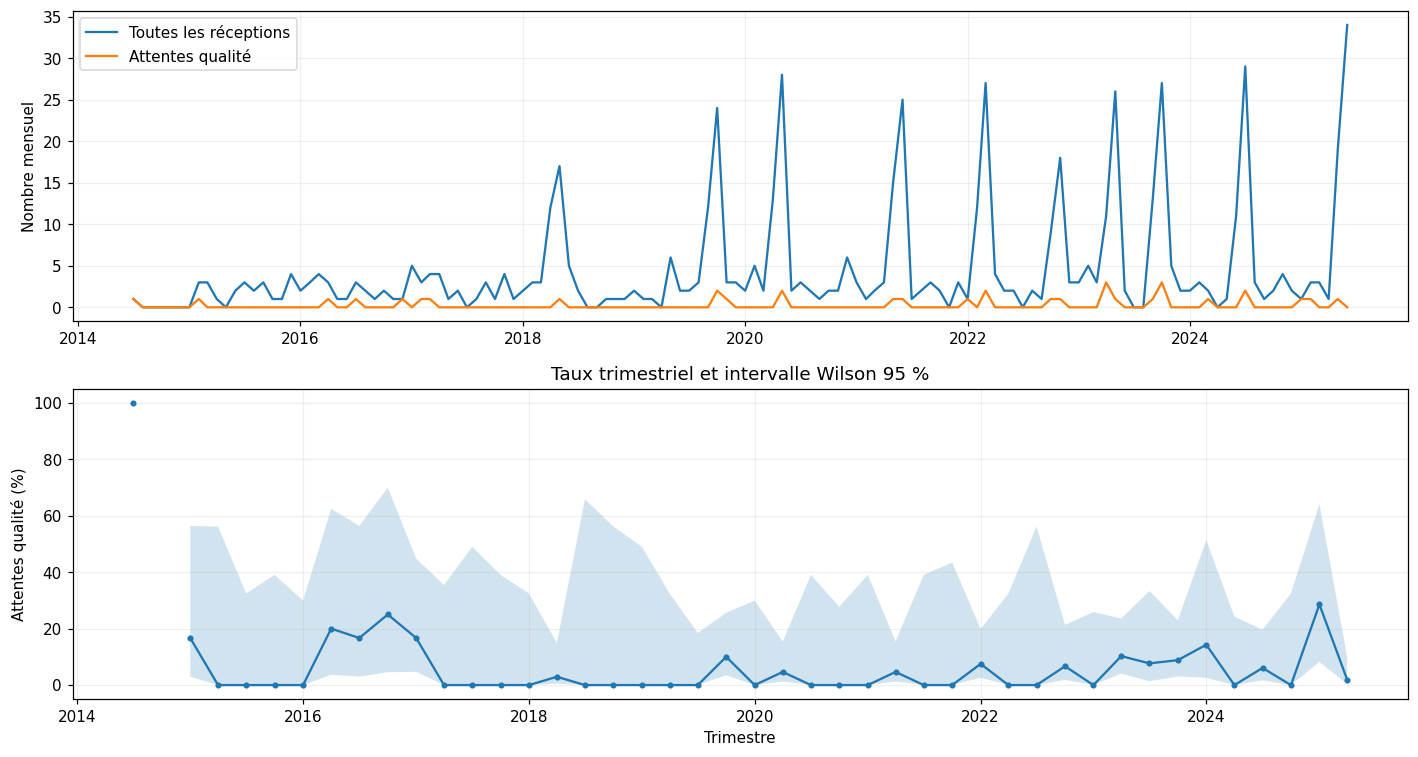

In [12]:
quarterly["low"], quarterly["high"] = wilson(
    quarterly.held, quarterly.n.replace(0, np.nan)
)
display(quarterly.tail(12))
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
axes[0].plot(monthly.index.to_timestamp(), monthly.n, label="Toutes les réceptions")
axes[0].plot(monthly.index.to_timestamp(), monthly.held, label="Attentes qualité")
axes[0].set_ylabel("Nombre mensuel")
axes[0].legend()
x = quarterly.index.to_timestamp()
axes[1].plot(x, 100 * quarterly.rate, marker="o", ms=3)
axes[1].fill_between(x, 100 * quarterly.low, 100 * quarterly.high, alpha=0.2)
axes[1].set_ylabel("Attentes qualité (%)")
axes[1].set_xlabel("Trimestre")
axes[1].set_title("Taux trimestriel et intervalle Wilson 95 %")
fig.tight_layout()
plt.show()


### Taux qualité selon établissement et trimestre


In [13]:
grid = pd.MultiIndex.from_product(
    [facility.index, quarters], names=["receiving_facility_code", "quarter"]
)
quality_by_period = (
    df.groupby(["receiving_facility_code", "quarter"])
    .agg(n=("receipt_number", "size"), held=("quality_hold", "sum"))
    .reindex(grid, fill_value=0)
)
quality_by_period["rate"] = quality_by_period.held / quality_by_period.n.replace(
    0, np.nan
)
quality_by_period["low"], quality_by_period["high"] = wilson(
    quality_by_period.held, quality_by_period.n.replace(0, np.nan)
)
assert quality_by_period.n.sum() == len(df)


n  held      rate       low      high
receiving_facility_code quarter                                        
FCL-1011                2019Q4    8     2  0.250000  0.071478  0.590730
                        2021Q2   10     1  0.100000  0.017876  0.404156
FCL-1010                2021Q2    8     1  0.125000  0.022417  0.470895
FCL-1007                2018Q2    6     1  0.166667  0.030053  0.563509
                        2023Q2    6     1  0.166667  0.030053  0.563509
FCL-1019                2022Q1    5     1  0.200000  0.036223  0.624472
FCL-1030                2023Q2    5     1  0.200000  0.036223  0.624472
FCL-1010                2025Q2    4     1  0.250000  0.045586  0.699364
FCL-1020                2022Q1    4     1  0.250000  0.045586  0.699364
FCL-1029                2020Q2    4     1  0.250000  0.045586  0.699364
FCL-1011                2017Q1    3     1  0.333333  0.061490  0.792345
                        2023Q4    3     1  0.333333  0.061490  0.792345
FCL-1007                2023Q4    3     1  0.333333  0.061490  0.792345
FCL-1019                2017Q1    3     1  0.333333  0.061490  0.792345
FCL-1016                2024Q3    3     1  0.333333  0.061490  0.792345

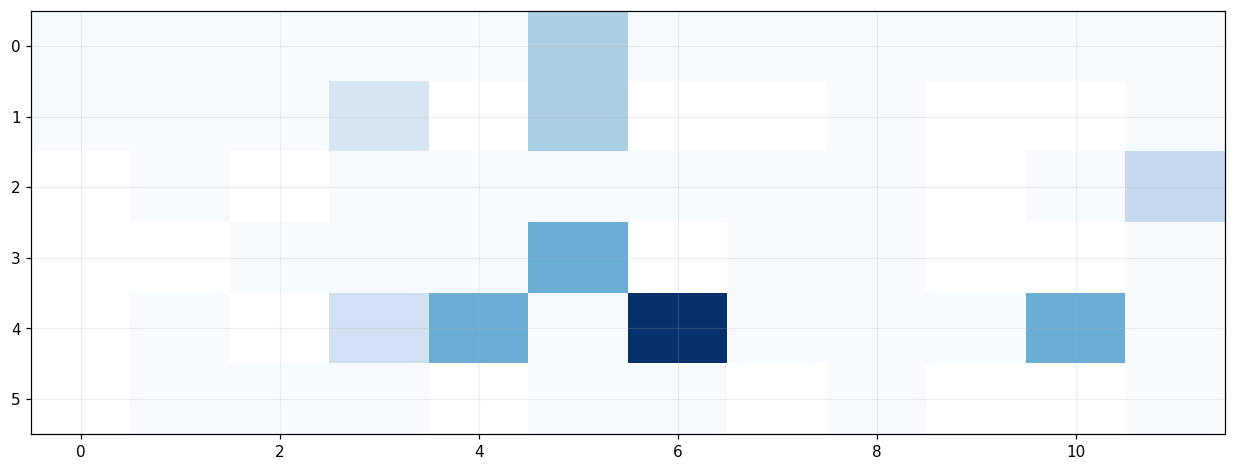

In [14]:
assert quality_by_period.held.sum() == df.quality_hold.sum()
display(
    quality_by_period.loc[quality_by_period.n.gt(0)]
    .sort_values(["held", "n"], ascending=False)
    .head(15)
)
recent_quarters = quarters[-12:]
leaders = facility.head(6).index
matrix = quality_by_period.rate.unstack().reindex(
    index=leaders, columns=recent_quarters
)
fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(
    np.ma.masked_invalid(matrix.to_numpy()), vmin=0, vmax=1, cmap="Blues", aspect="auto"
)


### Visualiser les attentes qualité par trimestre


In [15]:
ax.set_facecolor("#eeeeee")
for i, fac in enumerate(leaders):
    for j, q in enumerate(recent_quarters):
        row = quality_by_period.loc[(fac, q)]
        if row.n > 0:
            ax.text(
                j,
                i,
                f"{int(row.held)}/{int(row.n)}",
                ha="center",
                va="center",
                color="white" if row.rate > 0.5 else "black",
                fontsize=9,
            )


In [16]:
ax.set_xticks(
    range(len(recent_quarters)), recent_quarters.astype(str), rotation=45, ha="right"
)
ax.set_yticks(range(len(leaders)), leaders)
ax.set_title(
    "Attentes qualité par établissement et trimestre — texte = blocages/réceptions"
)
fig.colorbar(im, ax=ax, label="Proportion en attente (0 à 1)")
ax.grid(False)
fig.tight_layout()
plt.show()
quality_table = quality_by_period.reset_index()
print(f"Qualité par établissement et trimestre : {len(quality_table)} combinaisons.")
print("Trimestres avec au moins une réception (aperçu des 30 plus récents) :")
display(quality_table.loc[quality_table.n > 0].tail(30))


Qualité par établissement et trimestre : 1320 combinaisons.
Trimestres avec au moins une réception (aperçu des 30 plus récents) :


,receiving_facility_code,quarter,n,held,rate,low,high
959,FCL-1013,2023Q2,1,0,0.0,0.0,0.793457
967,FCL-1013,2025Q2,1,0,0.0,0.0,0.793457
995,FCL-1018,2021Q2,1,0,0.0,0.0,0.793457
998,FCL-1018,2022Q1,1,0,0.0,0.0,0.793457
1001,FCL-1018,2022Q4,1,0,0.0,0.0,0.793457
1004,FCL-1018,2023Q3,1,0,0.0,0.0,0.793457
1005,FCL-1018,2023Q4,1,0,0.0,0.0,0.793457
1033,FCL-1024,2019Q4,1,0,0.0,0.0,0.793457
1042,FCL-1024,2022Q1,1,0,0.0,0.0,0.793457
1047,FCL-1024,2023Q2,1,0,0.0,0.0,0.793457


In [17]:
print("Le tableau complet reste accessible dans la variable quality_table.")


Le tableau complet reste accessible dans la variable quality_table.


### Interpréter les taux


In [18]:
display(
    Markdown(
        "**Lecture :** une case à 100 % avec 1/1 ne documente pas le même niveau de risque que des blocages répétés sur un grand nombre de réceptions. Les zones grises ne prouvent pas une fermeture de site. Ces taux temporels restent descriptifs."
    )
)


**Lecture :** une case à 100 % avec 1/1 ne documente pas le même niveau de risque que des blocages répétés sur un grand nombre de réceptions. Les zones grises ne prouvent pas une fermeture de site. Ces taux temporels restent descriptifs.

# 3. Bloc 2 — Clustering des établissements


In [19]:
facility_months = df.groupby("receiving_facility_code").agg(
    receptions=("receipt_number", "size"),
    months_active=("month", "nunique"),
    quality_hold=("quality_hold", "sum"),
)
facility_months["mean_active_month"] = (
    facility_months.receptions / facility_months.months_active
)
facility_months["hold_rate"] = facility_months.quality_hold / facility_months.receptions
features_cluster = facility_months[
    ["receptions", "months_active", "mean_active_month", "hold_rate"]
].copy()


### Corrélations et nuages de points entre établissements


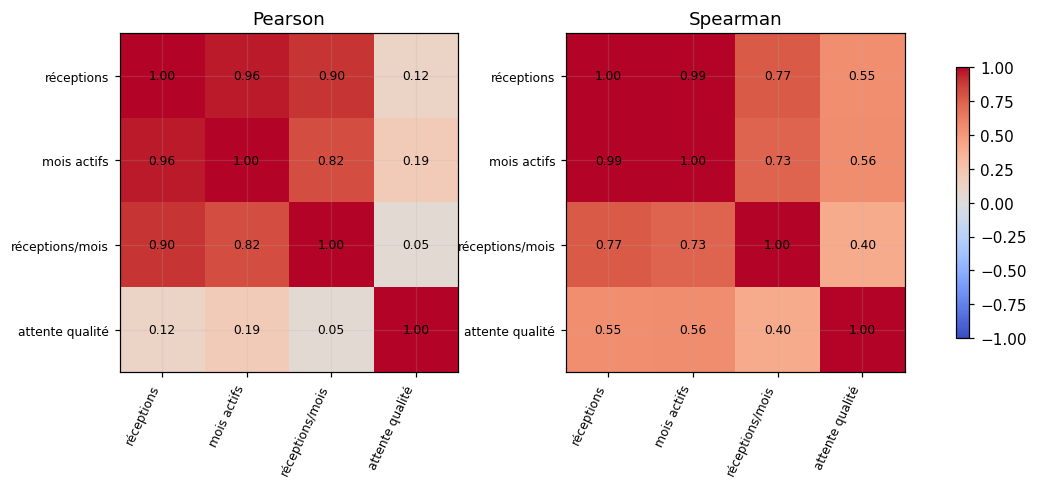

In [20]:
variables_fac = ["receptions", "months_active", "mean_active_month", "hold_rate"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, methode in zip(axes, ["pearson", "spearman"]):
    matrice = facility_months[variables_fac].corr(method=methode)
    image = ax.imshow(matrice, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(4), ["réceptions", "mois actifs", "réceptions/mois", "attente qualité"],
                  rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(4), ["réceptions", "mois actifs", "réceptions/mois", "attente qualité"], fontsize=8)
    for ligne in range(4):
        for colonne in range(4):
            ax.text(colonne, ligne, f"{matrice.iloc[ligne, colonne]:.2f}",
                    ha="center", va="center", fontsize=8)
    ax.set_title(methode.capitalize())
fig.colorbar(image, ax=axes, shrink=.8)
plt.show()


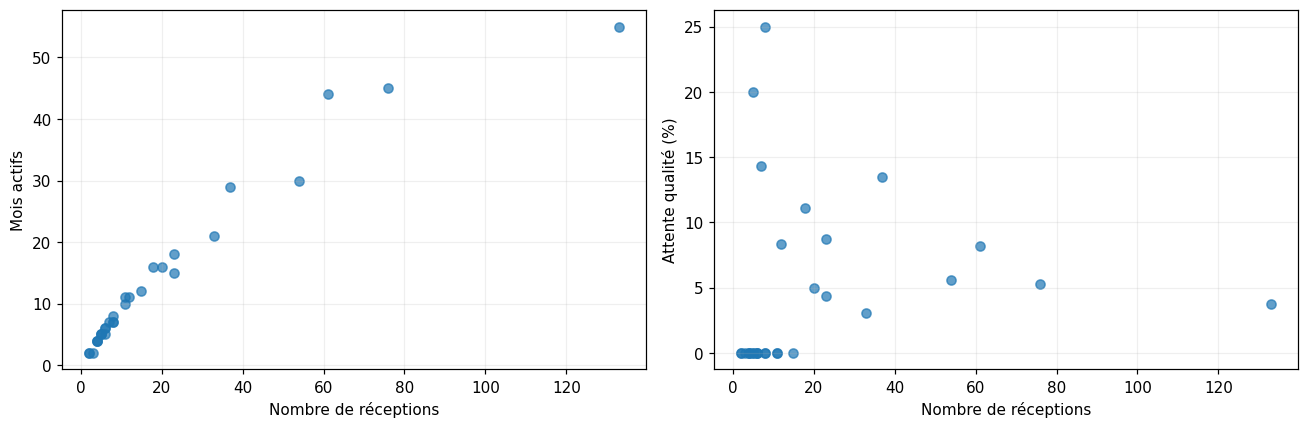

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(facility_months.receptions, facility_months.months_active, alpha=.7)
axes[0].set(xlabel="Nombre de réceptions", ylabel="Mois actifs")
axes[1].scatter(facility_months.receptions, facility_months.hold_rate * 100, alpha=.7)
axes[1].set(xlabel="Nombre de réceptions", ylabel="Attente qualité (%)")
plt.tight_layout();plt.show()


**Lecture :** les établissements ayant beaucoup de réceptions sont souvent présents sur davantage de mois. Les taux qualité sont plus instables sur de petits effectifs. Pearson et Spearman décrivent des associations, pas une cause. De plus, le nombre total et le nombre de mois actifs sont liés par construction.


In [22]:
for col in ["receptions", "months_active", "mean_active_month"]:
    features_cluster[col] = np.log1p(features_cluster[col])
X_facilities = StandardScaler().fit_transform(features_cluster)
clustering_scores = []
for k in [2, 3, 4]:
    model = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_facilities)
    clustering_scores.append(
        {"k": k, "silhouette": silhouette_score(X_facilities, model.labels_)}
    )
scores_facilities = pd.DataFrame(clustering_scores)
chosen_k = int(
    scores_facilities.sort_values(["silhouette", "k"], ascending=[False, True])
    .iloc[0]
    .k
)


### K-means : groupes et scores


In [23]:
kmeans_facilities = KMeans(n_clusters=chosen_k, n_init=20, random_state=42).fit(
    X_facilities
)
facility_months["cluster_exploratoire"] = kmeans_facilities.labels_
display(scores_facilities)
display(
    facility_months.groupby("cluster_exploratoire")
    .agg(
        n_etablissements=("receptions", "size"),
        receptions_mediane=("receptions", "median"),
        mois_actifs_median=("months_active", "median"),
        taux_attente_median=("hold_rate", "median"),
    )
    .round(3)
)


,k,silhouette
0,2,0.456436
1,3,0.488196
2,4,0.477634


,n_etablissements,receptions_mediane,mois_actifs_median,taux_attente_median
cluster_exploratoire,,,,
0,16,5.5,5.0,0.000
1,9,37.0,29.0,0.053
2,5,8.0,7.0,0.143


**Lecture des clusters :** K-Means distingue **trois groupes** parmi les 30 établissements. Le cluster 0 (16 établissements) est peu actif, avec une médiane de **5,5 réceptions**. Le cluster 1 (9 établissements) a un volume plus important (**37 réceptions** en médiane). Le cluster 2 (5 établissements) reçoit moins de marchandises mais a un taux médian d’attente qualité plus élevé (**14,3 %**). Attention : quand un établissement n'a que quelques réceptions, un seul `quality_hold` peut faire beaucoup monter son pourcentage. Ces clusters montrent des profils d'activité, pas des établissements fautifs.


Plus petits établissements : vérifier les dénominateurs avant de commenter un taux isolé.


,receptions,months_active,hold_rate,cluster_exploratoire
receiving_facility_code,,,,
FCL-1022,2,2,0.0,0
FCL-1017,2,2,0.0,0
FCL-1021,3,2,0.0,0
FCL-1027,4,4,0.0,0
FCL-1028,4,4,0.0,0
FCL-1026,4,4,0.0,0
FCL-1013,5,5,0.2,2
FCL-1018,5,5,0.0,0
FCL-1024,5,5,0.0,0


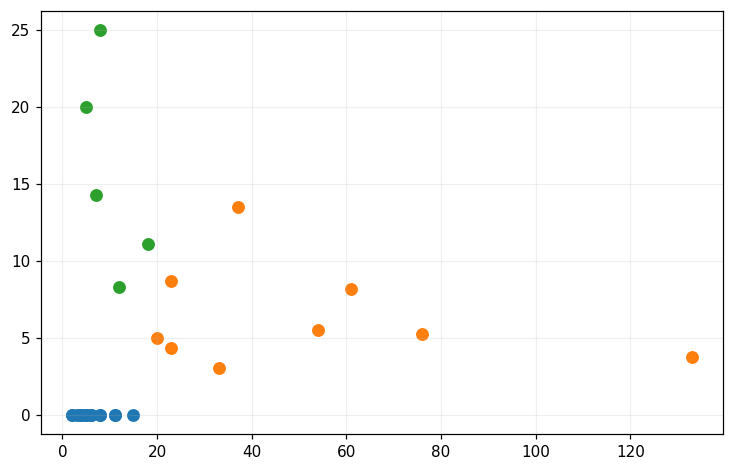

In [24]:
print(
    "Plus petits établissements : vérifier les dénominateurs avant de commenter un taux isolé."
)
display(
    facility_months[
        ["receptions", "months_active", "hold_rate", "cluster_exploratoire"]
    ]
    .sort_values("receptions")
    .head(10)
)
fig, ax = plt.subplots(figsize=(8, 5))
for cluster, part in facility_months.groupby("cluster_exploratoire"):
    ax.scatter(
        part.receptions,
        part.hold_rate * 100,
        label=f"Profil {cluster} (n={len(part)})",
        s=55,
    )


### Visualiser les groupes


In [25]:
ax.set(
    xlabel="Nombre de réceptions enregistrées",
    ylabel="Réceptions en quality_hold (%)",
    title="Typologie exploratoire des établissements",
)
ax.legend()
ax.grid(alpha=0.2)
plt.show()
print(
    "Conclusion : les profils d’activité contextualisent les taux ; la classification ne démontre pas une anomalie."
)


Conclusion : les profils d’activité contextualisent les taux ; la classification ne démontre pas une anomalie.


### CAH : dendrogramme des établissements


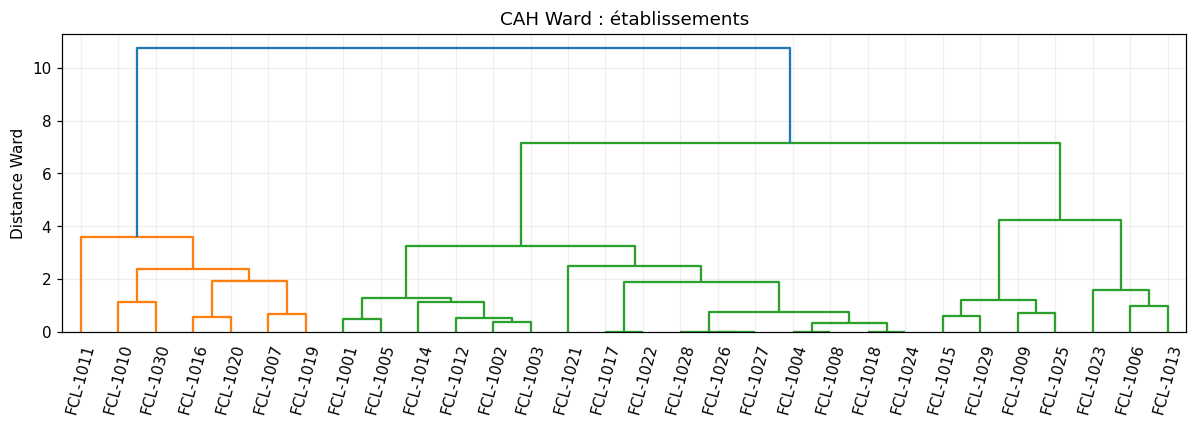

In [26]:
hierarchie_fac=linkage(X_facilities,method='ward')
fig,ax=plt.subplots(figsize=(11,4))
dendrogram(hierarchie_fac,labels=facility_months.index.tolist(),leaf_rotation=75,ax=ax)
ax.set(title='CAH Ward : établissements',ylabel='Distance Ward')
plt.tight_layout();plt.show()

### Comparer CAH et K-Means


In [27]:
profils_cah=AgglomerativeClustering(n_clusters=chosen_k,linkage='ward').fit_predict(X_facilities)
facility_months['cluster_CAH']=profils_cah
print('ARI K-Means / CAH :',round(adjusted_rand_score(
    facility_months.cluster_exploratoire,profils_cah),3))
display(pd.crosstab(facility_months.cluster_exploratoire,facility_months.cluster_CAH))

ARI K-Means / CAH : 0.883


cluster_CAH,0,1,2
cluster_exploratoire,,,
0,0,0,16
1,2,7,0
2,5,0,0


# 4. ACP et t-SNE


### a. ACP : profils des établissements


Variance expliquée : [0.688 0.241]


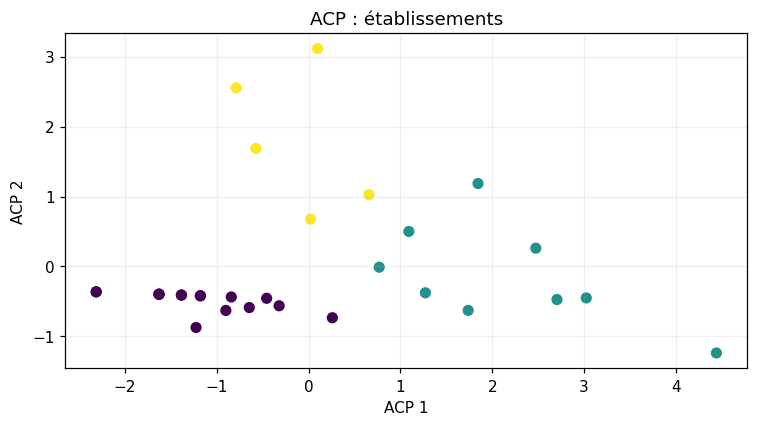

In [28]:
acp_fac = PCA(n_components=2).fit(X_facilities)
proj_acp_fac = acp_fac.transform(X_facilities)
print('Variance expliquée :',acp_fac.explained_variance_ratio_.round(3))
fig,ax=plt.subplots(figsize=(7,4))
ax.scatter(proj_acp_fac[:,0],proj_acp_fac[:,1],
           c=facility_months.cluster_exploratoire,s=40)
ax.set(title='ACP : établissements',xlabel='ACP 1',ylabel='ACP 2')
plt.tight_layout();plt.show()

### b. t-SNE : autre projection 2D


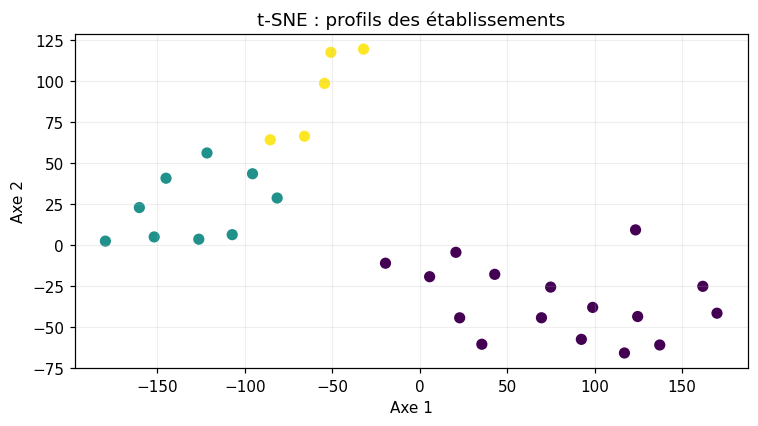

In [29]:
proj_tsne_fac=TSNE(n_components=2,perplexity=6,init='random',
    learning_rate='auto',random_state=42).fit_transform(X_facilities)
fig,ax=plt.subplots(figsize=(7,4))
ax.scatter(proj_tsne_fac[:,0],proj_tsne_fac[:,1],
           c=facility_months.cluster_exploratoire,s=40)
ax.set(title='t-SNE : profils des établissements',xlabel='Axe 1',ylabel='Axe 2')
plt.tight_layout();plt.show()

**Lecture :** ces deux projections illustrent les profils, elles ne détectent pas d’erreur.


# 5. Bloc 3 — Anomalies statistiques et taux qualité


**Pourquoi garder les cas atypiques ?** Un pic de réceptions peut être lié à une livraison groupée ou à la période étudiée. De même, `quality_hold` décrit une attente de contrôle qualité et ne prouve pas un problème de livraison. On conserve donc les lignes pour vérifier les commandes et les justificatifs avant toute conclusion.


### Corriger les tests multiples (BH)


In [30]:
def bh(pvalues):
    """Benjamini–Hochberg : ajustement descriptif des comparaisons multiples."""
    pvalues = np.asarray(pvalues, dtype=float)
    result = np.full(len(pvalues), np.nan)
    good = np.flatnonzero(np.isfinite(pvalues))
    if len(good):
        order = good[np.argsort(pvalues[good])]
        adjusted = pvalues[order] * len(good) / np.arange(1, len(good) + 1)
        result[order] = np.minimum.accumulate(adjusted[::-1])[::-1].clip(0, 1)
    return result


### Calculer les seuils IQR, Z-score et MAD


In [31]:
def seuils_pour_variable(x, min_n=8, haut_seul=False):
    valeurs = x.dropna()
    n = len(valeurs)
    q1, q3 = valeurs.quantile([.25, .75]) if n else (np.nan, np.nan)
    moyenne, ecart_type = valeurs.mean(), valeurs.std(ddof=1)
    mediane = valeurs.median()
    mad = (valeurs - mediane).abs().median()
    bornes = [
        ('IQR', q1-1.5*(q3-q1), q3+1.5*(q3-q1), x, q3-q1, 'hors Q1−1.5×IQR ; Q3+1.5×IQR'),
        ('Z-score', moyenne-3*ecart_type, moyenne+3*ecart_type,
         (x-moyenne)/ecart_type if ecart_type>0 else x*0+np.nan, ecart_type, '|z| > 3'),
        ('Z-modifie', mediane-3.5*mad/.6745, mediane+3.5*mad/.6745,
         .6745*(x-mediane)/mad if mad>0 else x*0+np.nan, mad, '|z_mod| > 3.5')]
    return n, bornes


### Identifier les observations atypiques


In [32]:
def lignes_signalees(g, cle, variable, groupe, min_n=8, haut_seul=False):
    x = pd.to_numeric(g[variable], errors='raise').replace([np.inf, -np.inf], np.nan)
    n, bornes = seuils_pour_variable(x, min_n, haut_seul)
    observations = []
    for methode, bas, haut, scores, ecart, regle in bornes:
        utilisable = n >= min_n and pd.notna(ecart) and ecart > 1e-12
        if haut_seul:
            bas = -np.inf
            regle += ' (queue haute uniquement)'
        for idx in g.index:
            valeur = x.loc[idx]
            applicable = bool(utilisable and pd.notna(valeur))
            observations.append(dict(
                observation=str(g.at[idx, cle]), groupe=groupe, variable=variable,
                methode=methode, valeur=valeur,
                score=scores.loc[idx] if applicable else np.nan,
                borne_basse=bas if utilisable else np.nan,
                borne_haute=haut if utilisable else np.nan, n_reference=n,
                applicable=applicable,
                signalee=bool(applicable and (valeur < bas or valeur > haut)),
                regle=regle if utilisable else f'Non évalué : n < {min_n} ou dispersion nulle',
                interpretation='Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.'))
    return observations


### Appliquer les tests statistiques


In [33]:
def statistiques(data, cle, variables, groupes=(), min_n=8, haut_seul=False):
    """IQR, Z et MAD par groupe comparable ; pas d'imputation."""
    tous = []
    parts = (data.groupby(list(groupes), dropna=False, sort=True)
             if groupes else [('ensemble', data)])
    for identifiant, part in parts:
        if groupes:
            valeurs = identifiant if isinstance(identifiant, tuple) else (identifiant,)
            etiquette = '; '.join(f'{col}={val}' for col, val in zip(groupes, valeurs))
        else:
            etiquette = 'ensemble'
        for variable in variables:
            tous.extend(lignes_signalees(part, cle, variable, etiquette, min_n, haut_seul))
    return pd.DataFrame(tous)


### Résumer les tests


In [34]:
def resume_tests(tests):
    display(
        tests.groupby(["variable", "methode"])
        .agg(evaluations=("applicable", "sum"), signalees=("signalee", "sum"))
        .reset_index()
    )
    skipped = tests.loc[
        ~tests.applicable, ["groupe", "variable", "methode", "regle"]
    ].drop_duplicates()
    if len(skipped):
        print("Cas non évalués (extrait) :")
        display(skipped.head(12))


### Construire les séries mensuelles


In [35]:
def frequences(data, facility, date):
    """Panel entre premier et dernier mois observés, y compris les zéros enregistrés."""
    frames = []
    for name, g in data.groupby(facility):
        periods = g[date].dt.to_period("M")
        grid = pd.period_range(periods.min(), periods.max(), freq="M")
        counts = periods.value_counts().reindex(grid, fill_value=0).sort_index()
        out = pd.DataFrame(
            {"etablissement": name, "mois": grid.to_timestamp(), "n": counts.values}
        )
        # Bords exclus : premier/dernier mois d'activité observée potentiellement incomplets.
        out["interieur"] = (np.arange(len(out)) > 0) & (
            np.arange(len(out)) < len(out) - 1
        )
        out["historique_12"] = out["n"].shift(1).rolling(12, min_periods=12).sum()
        past_complete = (
            out["interieur"].shift(1).rolling(12, min_periods=12).sum().eq(12)
        )
        out["eligible"] = out["interieur"] & past_complete
        out["p_pic"] = np.nan
        ix = out["eligible"]
        # Sous un taux constant, conditionnellement au total, le mois testé représente 1/13 de l'exposition.
        total = (out.loc[ix, "historique_12"] + out.loc[ix, "n"]).astype(int)
        out.loc[ix, "p_pic"] = binom.sf(out.loc[ix, "n"] - 1, total, 1 / 13)
        out["observation"] = str(name) + "|" + out["mois"].dt.strftime("%Y-%m")
        frames.append(out)
    out = pd.concat(frames, ignore_index=True)
    out["q_pic"] = bh(out.p_pic)
    out["pic_BH"] = out.q_pic.lt(0.05)
    return out


### Tester les pics mensuels


In [36]:
def test_pics(panel):
    result = pd.DataFrame(
        {
            "observation": panel.observation,
            "groupe": panel.etablissement,
            "variable": "nombre_mensuel",
            "methode": "Binomial_conditionnel_BH",
            "valeur": panel.n,
            "score": panel.q_pic,
            "historique_12": panel.historique_12,
            "p_brut": panel.p_pic,
            "borne_basse": 0.0,
            "borne_haute": 0.05,
            "n_reference": 12,
            "applicable": panel.eligible,
            "signalee": panel.pic_BH,
            "regle": "q_BH < 0.05 ; comparaison aux 12 mois précédents, bords exclus",
            "interpretation": "Pic exploratoire sous hypothèse de taux constant et couverture continue ; vérifier collecte et saisonnalité.",
        }
    )
    return result


In [37]:
panel = frequences(df, "receiving_facility_code", "receipt_date")
interior = panel.loc[panel.interieur].copy()
tests = statistiques(
    interior, "observation", ["n"], ["etablissement"], min_n=12, haut_seul=True
)
resume_tests(tests)
peaks = test_pics(panel)
print("Mois testés contre historique de 12 mois :", panel.eligible.sum())
print("Pics p<0.05 avant correction :", panel.p_pic.lt(0.05).sum())
print("Pics q<0.05 après correction BH :", panel.pic_BH.sum())
display(
    panel.loc[panel.eligible].nsmallest(12, "q_pic")[
        ["observation", "n", "historique_12", "p_pic", "q_pic", "pic_BH"]
    ]
)


Cas non évalués (extrait) :
Mois testés contre historique de 12 mois : 2298
Pics p<0.05 avant correction : 53
Pics q<0.05 après correction BH : 3


,variable,methode,evaluations,signalees
0,n,IQR,375,26
1,n,Z-modifie,0,0
2,n,Z-score,2538,96


,groupe,variable,methode,regle
0,etablissement=FCL-1001,n,IQR,Non évalué : n < 12 ou dispersion nulle
128,etablissement=FCL-1001,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
192,etablissement=FCL-1002,n,IQR,Non évalué : n < 12 ou dispersion nulle
390,etablissement=FCL-1002,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
489,etablissement=FCL-1003,n,IQR,Non évalué : n < 12 ou dispersion nulle
685,etablissement=FCL-1003,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
783,etablissement=FCL-1004,n,IQR,Non évalué : n < 12 ou dispersion nulle
935,etablissement=FCL-1004,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
1011,etablissement=FCL-1005,n,IQR,Non évalué : n < 12 ou dispersion nulle
1185,etablissement=FCL-1005,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle


,observation,n,historique_12,p_pic,q_pic,pic_BH
1061,FCL-1011|2018-05,6,0.0,2.071762e-07,0.000353,True
1098,FCL-1011|2021-06,9,6.0,3.071393e-07,0.000353,True
1107,FCL-1011|2022-03,9,14.0,2.837454e-05,0.021735,True
653,FCL-1007|2024-07,5,3.0,1.236891e-04,0.071059,False
1078,FCL-1011|2019-10,7,10.0,1.549973e-04,0.071237,False
1115,FCL-1011|2022-11,8,16.0,2.928017e-04,0.112143,False
974,FCL-1010|2021-06,5,6.0,8.378832e-04,0.275065,False
2675,FCL-1030|2023-05,4,3.0,1.013394e-03,0.291098,False
596,FCL-1007|2019-10,5,7.0,1.345414e-03,0.328542,False
1641,FCL-1016|2023-05,3,1.0,1.715626e-03,0.328542,False


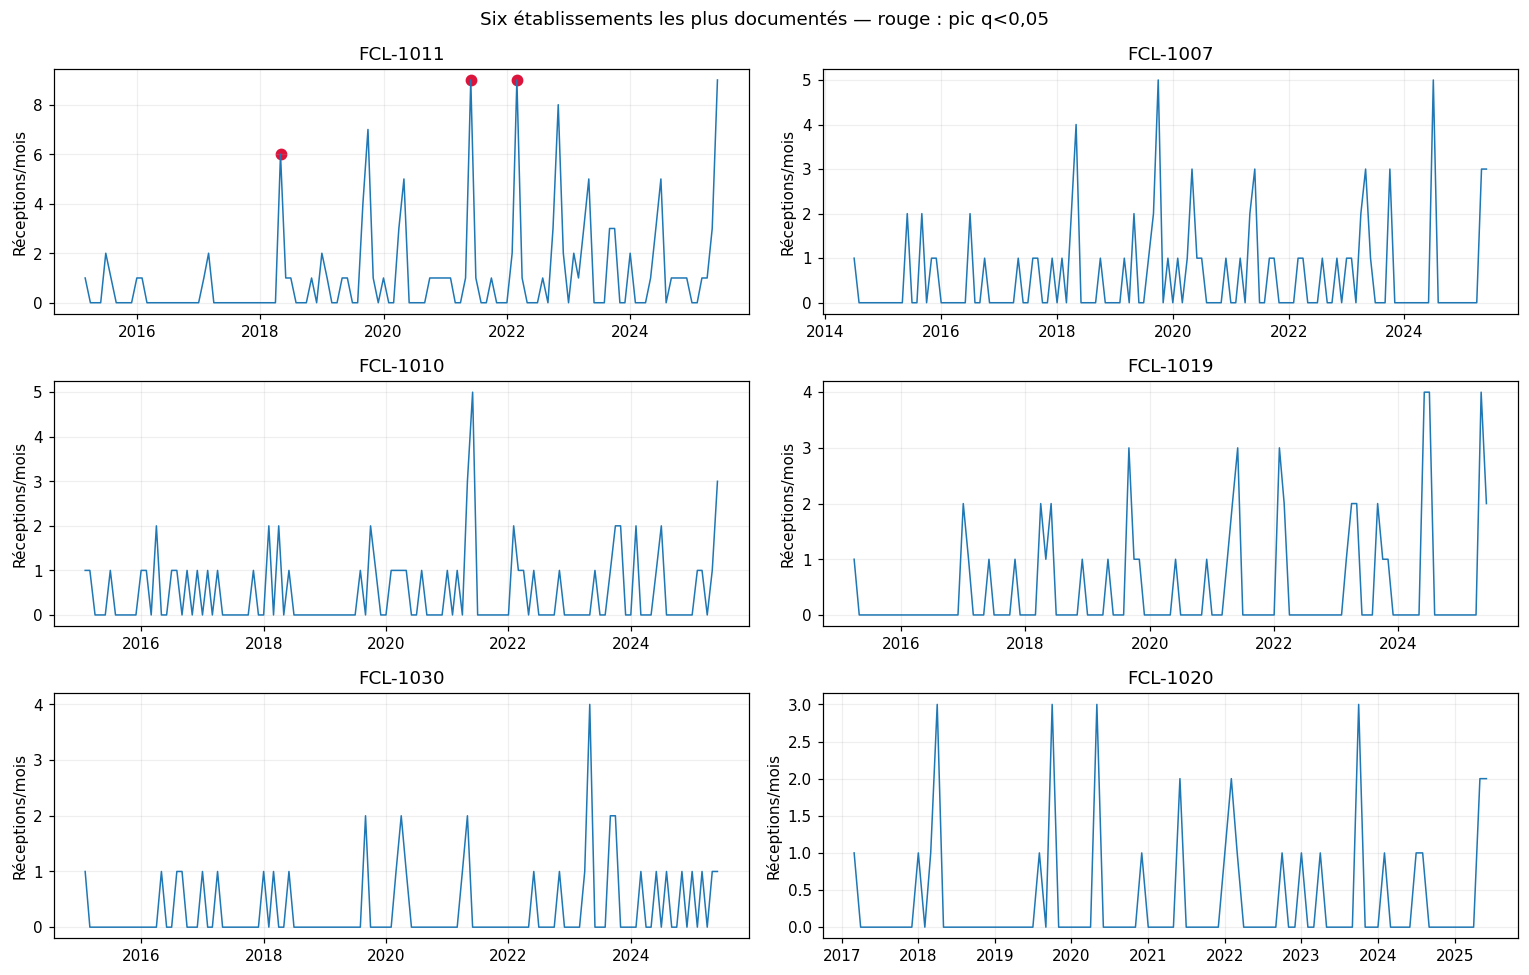

In [38]:
members = df.groupby(["receiving_facility_code", "month"]).receipt_number.agg(
    lambda x: "; ".join(x)
)
panel["observations_sources"] = [
    members.get((f, pd.Period(m, freq="M")), "[aucune réception enregistrée]")
    for f, m in zip(panel.etablissement, panel.mois)
]
top = facility.head(6).index
fig, axes = plt.subplots(3, 2, figsize=(14, 9))
for ax, name in zip(axes.flat, top):
    g = panel.loc[panel.etablissement.eq(name)]
    ax.plot(g.mois, g.n, lw=1)
    marked = g.pic_BH
    ax.scatter(g.loc[marked, "mois"], g.loc[marked, "n"], c="crimson", s=45)
    ax.set_title(name)
    ax.set_ylabel("Réceptions/mois")
fig.suptitle("Six établissements les plus documentés — rouge : pic q<0,05")
fig.tight_layout()
plt.show()


In [39]:
display(
    Markdown(
        "**Lecture :** le volume total élevé d'un établissement n'est pas en lui-même une anomalie. Les pics sont évalués par rapport à son historique. Les signaux IQR/Z non confirmés par le test conditionnel restent exploratoires."
    )
)


**Lecture :** le volume total élevé d'un établissement n'est pas en lui-même une anomalie. Les pics sont évalués par rapport à son historique. Les signaux IQR/Z non confirmés par le test conditionnel restent exploratoires.

### Comparer les taux qualité (Fisher, BH)


In [40]:
total_held = int(df.quality_hold.sum())
total_n = len(df)
facility["p_fisher"] = [
    fisher_exact(
        [
            [int(row.held), int(row.n - row.held)],
            [
                total_held - int(row.held),
                (total_n - int(row.n)) - (total_held - int(row.held)),
            ],
        ],
        alternative="greater",
    ).pvalue
    for _, row in facility.iterrows()
]


In [41]:
facility["q_fisher"] = bh(facility.p_fisher)
facility["atypique"] = facility.q_fisher.lt(0.05)
display(facility.sort_values("rate", ascending=False))


,n,held,rate,low,high,p_fisher,q_fisher,atypique
receiving_facility_code,,,,,,,,
FCL-1023,8,2,0.250000,0.071478,0.590730,0.068381,1.0,False
FCL-1013,5,1,0.200000,0.036223,0.624472,0.250035,1.0,False
FCL-1006,7,1,0.142857,0.025679,0.513135,0.332026,1.0,False
FCL-1030,37,5,0.135135,0.059132,0.279777,0.047480,1.0,False
FCL-1025,18,2,0.111111,0.031019,0.328002,0.265057,1.0,False
FCL-1015,23,2,0.086957,0.024179,0.267964,0.371192,1.0,False
FCL-1009,12,1,0.083333,0.014865,0.353886,0.500769,1.0,False
FCL-1010,61,5,0.081967,0.035519,0.177949,0.245625,1.0,False
FCL-1019,54,3,0.055556,0.019073,0.151075,0.595680,1.0,False


In [42]:
quality_tests = pd.DataFrame(
    {
        "observation": facility.index,
        "groupe": "établissement versus tous les autres",
        "variable": "taux_quality_hold",
        "methode": "Fisher_exact_BH",
        "valeur": facility.rate,
        "score": facility.q_fisher,
        "borne_basse": 0.0,
        "borne_haute": 0.05,
        "n_reference": facility.n,
        "applicable": True,
        "signalee": facility.atypique,
        "regle": "q_BH < 0.05 ; Fisher unilatéral",
        "interpretation": "Taux élevé relativement aux autres ; ajuster au type de marchandises et à la période avant toute conclusion.",
        "effectif": facility.n,
        "attentes": facility.held,
        "IC95_bas": facility.low,
        "IC95_haut": facility.high,
    }
).reset_index(drop=True)


In [43]:
display(
    Markdown(
        f"**Lecture calculée :** {int(facility.atypique.sum())} établissement(s) au-dessus du seuil "
        "après correction BH. Un taux brut élevé avec peu de réceptions peut rester compatible avec la variabilité d'échantillonnage."
    )
)


**Lecture calculée :** 0 établissement(s) au-dessus du seuil après correction BH. Un taux brut élevé avec peu de réceptions peut rester compatible avec la variabilité d'échantillonnage.

### Regrouper les observations signalées


### Construire le tableau des anomalies


In [44]:
def bilan(tests, nom, domaine):
    """Affiche les anomalies et seuils dans le notebook, sans créer de CSV."""
    tests = tests.copy()
    tests["echelle_seuil"] = np.where(
        tests.methode.isin(
            ["Binomial_conditionnel_BH", "Fisher_exact_BH", "IF", "LOF", "LOF_k5"]
        ),
        "score",
        "valeur",
    )
    flagged = tests.loc[tests.signalee].copy()
    cols = [
        "groupe", "variable", "methode", "borne_basse", "borne_haute",
        "n_reference", "regle", "echelle_seuil",
    ]
    seuils = tests[cols].drop_duplicates().reset_index(drop=True)
    assert flagged.observation.notna().all()
    print(
        f"{len(flagged)} détections ; {flagged.observation.nunique()} identifiants distincts "
        "(plusieurs méthodes peuvent signaler une même observation)."
    )
    print("Anomalies détectées :")
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(flagged.reset_index(drop=True))
    print(f"Seuils utilisés : {len(seuils)} combinaisons (premières 20 lignes) :")
    display(seuils.head(20))
    return flagged


In [45]:
all_tests = pd.concat([tests, peaks, quality_tests], ignore_index=True)
all_tests = all_tests.merge(
    panel[["observation", "observations_sources"]],
    on="observation",
    how="left",
    validate="many_to_one",
)
facility_members = df.groupby("receiving_facility_code").receipt_number.agg(
    lambda x: "; ".join(x)
)
all_tests["observations_sources"] = all_tests.observations_sources.fillna(
    all_tests.observation.map(facility_members)
)
register = bilan(all_tests, "goods_receipts", "logistics")
highest = facility.sort_values("rate", ascending=False).iloc[0]


125 détections ; 113 identifiants distincts (plusieurs méthodes peuvent signaler une même observation).
Anomalies détectées :
Seuils utilisés : 139 combinaisons (premières 20 lignes) :


,observation,groupe,variable,methode,valeur,score,borne_basse,borne_haute,n_reference,...,interpretation,historique_12,p_brut,effectif,attentes,IC95_bas,IC95_haut,observations_sources,echelle_seuil
0,FCL-1001|2020-05,etablissement=FCL-1001,n,Z-score,2.0,5.548002,-inf,1.124526,64,...,"Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.",NaN,NaN,NaN,NaN,NaN,NaN,RCV-2020-00217; RCV-2020-00220,valeur
1,FCL-1002|2016-11,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,"Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.",NaN,NaN,NaN,NaN,NaN,NaN,RCV-2016-00046,valeur
2,FCL-1002|2018-04,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,"Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.",NaN,NaN,NaN,NaN,NaN,NaN,RCV-2018-00088,valeur
3,FCL-1002|2019-10,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,"Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.",NaN,NaN,NaN,NaN,NaN,NaN,RCV-2019-00162,valeur
4,FCL-1002|2021-05,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,"Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.",NaN,NaN,NaN,NaN,NaN,NaN,RCV-2021-00272,valeur
5,FCL-1002|2021-09,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,"Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.",NaN,NaN,NaN,NaN,NaN,NaN,RCV-2021-00304,valeur
6,FCL-1002|2022-11,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,"Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.",NaN,NaN,NaN,NaN,NaN,NaN,RCV-2022-00384,valeur
7,FCL-1002|2023-10,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,"Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.",NaN,NaN,NaN,NaN,NaN,NaN,RCV-2023-00458,valeur
8,FCL-1002|2023-11,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,"Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.",NaN,NaN,NaN,NaN,NaN,NaN,RCV-2023-00475,valeur
9,FCL-1003|2017-11,etablissement=FCL-1003,n,Z-score,1.0,3.128575,-inf,0.962677,98,...,"Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.",NaN,NaN,NaN,NaN,NaN,NaN,RCV-2017-00076,valeur


,groupe,variable,methode,borne_basse,borne_haute,n_reference,regle,echelle_seuil
0,etablissement=FCL-1001,n,IQR,NaN,NaN,64,Non évalué : n < 12 ou dispersion nulle,valeur
1,etablissement=FCL-1001,n,Z-score,-inf,1.124526,64,|z| > 3 (queue haute uniquement),valeur
2,etablissement=FCL-1001,n,Z-modifie,NaN,NaN,64,Non évalué : n < 12 ou dispersion nulle,valeur
3,etablissement=FCL-1002,n,IQR,NaN,NaN,99,Non évalué : n < 12 ou dispersion nulle,valeur
4,etablissement=FCL-1002,n,Z-score,-inf,0.902589,99,|z| > 3 (queue haute uniquement),valeur
5,etablissement=FCL-1002,n,Z-modifie,NaN,NaN,99,Non évalué : n < 12 ou dispersion nulle,valeur
6,etablissement=FCL-1003,n,IQR,NaN,NaN,98,Non évalué : n < 12 ou dispersion nulle,valeur
7,etablissement=FCL-1003,n,Z-score,-inf,0.962677,98,|z| > 3 (queue haute uniquement),valeur
8,etablissement=FCL-1003,n,Z-modifie,NaN,NaN,98,Non évalué : n < 12 ou dispersion nulle,valeur
9,etablissement=FCL-1004,n,IQR,NaN,NaN,76,Non évalué : n < 12 ou dispersion nulle,valeur


In [46]:
highest_id = facility.sort_values("rate", ascending=False).index[0]
summary = {
    "n": len(df),
    "held": total_held,
    "rate": float(global_rate),
    "conditional_peaks": int(panel.pic_BH.sum()),
    "fisher_facilities": int(facility.atypique.sum()),
    "stats_months": int(tests.loc[tests.signalee, "observation"].nunique()),
    "highest_rate_facility": highest_id,
    "highest_rate": float(highest.rate),
    "highest_n": int(highest.n),
    "largest_volume_facility": facility.index[0],
    "largest_volume_n": int(facility.iloc[0].n),
}


In [47]:
display(
    Markdown(
        f"**Bilan calculé :** {total_held}/{total_n} réceptions en attente qualité ({global_rate:.2%}). "
        f"{summary['stats_months']} mois signalés par au moins un test IQR/Z ; "
        f"{summary['conditional_peaks']} pics de fréquence et {summary['fisher_facilities']} taux d'établissement "
        "retenus après BH. "
        f"Le taux brut maximal est celui de {highest_id} : {int(highest.held)}/{int(highest.n)}. "
        "Les intervalles et les effectifs priment sur un classement des seuls pourcentages."
    )
)
assert monthly.n.sum() == len(df)
assert panel.n.sum() == len(df)
assert facility.held.sum() == df.quality_hold.sum()
assert panel.loc[panel.pic_BH, "eligible"].all()


**Bilan calculé :** 34/610 réceptions en attente qualité (5.57%). 113 mois signalés par au moins un test IQR/Z ; 3 pics de fréquence et 0 taux d'établissement retenus après BH. Le taux brut maximal est celui de FCL-1023 : 2/8. Les intervalles et les effectifs priment sur un classement des seuls pourcentages.

### Rapprocher les commandes


In [48]:
orders_path = ROOT / "data/logistics/cleaned/purchase_order_lines_clean.csv"
orders = pd.read_csv(orders_path)
keys = ["purchase_order_number", "purchase_order_line"]
assert not orders.duplicated(keys).any(), "Clé de commande non unique"


In [49]:
received = df.merge(
    (
        orders[keys + ["ordered_quantity", "ordered_unit", "receiving_facility_code"]]
        if "receiving_facility_code" in orders.columns
        else orders[
            keys + ["ordered_quantity", "ordered_unit", "ordering_facility_code"]
        ]
    ),
    on=keys,
    how="left",
    validate="many_to_one",
    indicator=True,
    suffixes=("_receipt", "_order"),
)


In [50]:
received["received_quantity"] = pd.to_numeric(
    received.received_quantity, errors="raise"
)
received["ordered_quantity"] = pd.to_numeric(received.ordered_quantity, errors="coerce")
print(
    "Réceptions sans commande retrouvée :", int(received._merge.eq("left_only").sum())
)


Réceptions sans commande retrouvée : 0


In [51]:
print(
    "Désaccord d’unité :",
    int(
        (
            received.received_unit.ne(received.ordered_unit)
            & received._merge.eq("both")
        ).sum()
    ),
)


Désaccord d’unité : 0


### Comparer quantités commandées et reçues


In [52]:
qty = (
    received.groupby(keys)
    .agg(
        total_received=("received_quantity", "sum"),
        ordered_quantity=("ordered_quantity", "first"),
        n_receipts=("receipt_number", "size"),
    )
    .reset_index()
)
qty["difference"] = qty.total_received - qty.ordered_quantity
print(
    "Lignes de commande avec réception inférieure à la quantité commandée :",
    int(qty.difference.lt(-1e-8).sum()),
)


Lignes de commande avec réception inférieure à la quantité commandée : 65


In [53]:
print(
    "Lignes de commande avec réception supérieure :", int(qty.difference.gt(1e-8).sum())
)
print("Attentes qualité selon inspection (valeur inconnue conservée) :")
display(pd.crosstab(df.receipt_status, df.inspection_status.fillna("[non renseignée]")))
display(qty.loc[qty.difference.lt(-1e-8)].sort_values("difference").head(10))
assert len(received) == len(df)
print(
    "Interprétation : écarts documentaires à examiner avec les statuts des commandes et les dates ; aucun défaut de livraison n’est affirmé."
)


Lignes de commande avec réception supérieure : 0
Attentes qualité selon inspection (valeur inconnue conservée) :
Interprétation : écarts documentaires à examiner avec les statuts des commandes et les dates ; aucun défaut de livraison n’est affirmé.


inspection_status,[non renseignée],accepted,conditional,held
receipt_status,,,,
posted,4,505,67,0
quality_hold,0,0,0,34


,purchase_order_number,purchase_order_line,total_received,ordered_quantity,n_receipts,difference
446,PO-2023-00061,1,65.90,84,1,-18.10
129,PO-2019-00005,1,65.23,83,1,-17.77
87,PO-2018-00010,1,69.37,82,1,-12.63
533,PO-2024-00045,1,58.28,69,1,-10.72
411,PO-2023-00023,1,59.81,70,1,-10.19
381,PO-2022-00075,1,37.90,47,1,-9.10
149,PO-2019-00026,1,37.14,45,1,-7.86
422,PO-2023-00037,1,35.65,43,1,-7.35
310,PO-2021-00060,1,23.41,30,1,-6.59
403,PO-2023-00012,1,40.60,47,1,-6.40


# 6. Isolation Forest, LOF et DBSCAN


### Isolation Forest sur les établissements


In [54]:
if_fac=IsolationForest(n_estimators=200,contamination=.05,random_state=42)
facility_months['IF_flag']=if_fac.fit_predict(X_facilities)==-1
display(facility_months.loc[facility_months.IF_flag,
    ['receptions','months_active','hold_rate']])

,receptions,months_active,hold_rate
receiving_facility_code,,,
FCL-1011,133,55,0.037594
FCL-1021,3,2,0.000000


### LOF sur les établissements


In [55]:
lof_fac=LocalOutlierFactor(n_neighbors=8,contamination='auto')
lof_fac.fit_predict(X_facilities)
facility_months['LOF_score']=-lof_fac.negative_outlier_factor_
facility_months['LOF_flag']=facility_months.LOF_score.gt(1.5)
display(facility_months.loc[facility_months.LOF_flag,
    ['receptions','months_active','hold_rate','LOF_score']].round(2))

,receptions,months_active,hold_rate,LOF_score
receiving_facility_code,,,,
FCL-1006,7,7,0.14,1.63
FCL-1011,133,55,0.04,1.69
FCL-1013,5,5,0.20,2.02
FCL-1021,3,2,0.00,2.01
FCL-1023,8,7,0.25,1.57


### DBSCAN : établissements isolés


In [56]:
db_fac=DBSCAN(eps=1.5,min_samples=3).fit_predict(X_facilities)
facility_months['DBSCAN_bruit']=db_fac==-1
print('Établissements isolés :',int(facility_months.DBSCAN_bruit.sum()))

Établissements isolés : 1


### Comparer les détections


In [57]:
display(facility_months.loc[
    facility_months.IF_flag | facility_months.LOF_flag | facility_months.DBSCAN_bruit,
    ['receptions','hold_rate','IF_flag','LOF_flag','DBSCAN_bruit']])

,receptions,hold_rate,IF_flag,LOF_flag,DBSCAN_bruit
receiving_facility_code,,,,,
FCL-1006,7,0.142857,False,True,False
FCL-1011,133,0.037594,True,True,True
FCL-1013,5,0.200000,False,True,False
FCL-1021,3,0.000000,True,True,False
FCL-1023,8,0.250000,False,True,False


**Lecture :** IF impose 5 % de cas ; LOF/DBSCAN dépendent des paramètres et des profils d’activité.


# 7. Apriori et rapprochements


### Construire les paniers de réceptions


In [58]:
paniers_goods=[{
    'unite='+str(r.received_unit),
    'inspection='+('non_renseignee' if pd.isna(r.inspection_status) else str(r.inspection_status)),
    'statut='+str(r.receipt_status),
    'volume='+('haut' if r.received_quantity>=df.loc[df.received_unit.eq(r.received_unit),'received_quantity'].median() else 'bas')}
    for r in df.itertuples()]
print('Réceptions :',len(paniers_goods))

Réceptions : 610


### Rechercher les ensembles fréquents


In [59]:
def apriori_itemsets(transactions, min_support=.08, max_size=3):
    """Apriori : construire et élaguer des ensembles fréquents de taille 1 à 3."""
    paniers=[set(t) for t in transactions]
    n=len(paniers)
    counts=Counter(item for panier in paniers for item in panier)
    freq={frozenset([x]):v/n for x,v in counts.items() if v/n>=min_support}
    all_freq=dict(freq)
    for k in range(2,max_size+1):
        uniques=sorted(set().union(*[set(f) for f in freq])) if freq else []
        candidates=(frozenset(combo) for combo in combinations(uniques,k))
        candidates=[c for c in candidates if all(frozenset(s) in freq
                        for s in combinations(c,k-1))]
        freq={c:sum(c<=panier for panier in paniers)/n for c in candidates}
        freq={c:s for c,s in freq.items() if s>=min_support}
        all_freq.update(freq)
    return all_freq

In [60]:
freq_goods=apriori_itemsets(paniers_goods, min_support=0.06, max_size=3)
print('Ensembles fréquents :',len(freq_goods))

Ensembles fréquents : 52


### Lire les règles d’association


In [61]:
def regles_apriori(freq, min_confiance=.6, min_lift=1.1):
    """Extraire support, confiance et lift pour toutes les règles fréquentes."""
    lignes=[]
    for ensemble,support in freq.items():
        if len(ensemble)<2:continue
        for taille in range(1,len(ensemble)):
            for part in combinations(sorted(ensemble),taille):
                gauche=frozenset(part);droite=ensemble-gauche
                confiance=support/freq[gauche]
                lift=confiance/freq[droite]
                if confiance>=min_confiance and lift>=min_lift:
                    lignes.append({'antecedent':' + '.join(sorted(gauche)),
                        'consequent':' + '.join(sorted(droite)),
                        'support':support,'confiance':confiance,'lift':lift})
    return pd.DataFrame(lignes,columns=['antecedent','consequent',
                                        'support','confiance','lift'])

In [62]:
regles_goods=regles_apriori(freq_goods)
print('Règles retenues :',len(regles_goods))
display(regles_goods.sort_values('lift',ascending=False).head(12).round(3))

Règles retenues : 5


,antecedent,consequent,support,confiance,lift
2,inspection=accepted + unite=service,volume=haut,0.141,0.860,1.453
0,unite=service,volume=haut,0.170,0.860,1.452
4,statut=posted + unite=service,volume=haut,0.159,0.858,1.450
1,unite=service,inspection=accepted + volume=haut,0.141,0.711,1.445
3,unite=service,statut=posted + volume=haut,0.159,0.802,1.434


→ Résultat exploratoire : une association fréquente ne prouve pas une cause.


### Croiser les pics et les statuts


In [63]:
pics_facility=panel.loc[panel.pic_BH,['etablissement','mois']].copy()
print('Pics mensuels confirmés BH :',len(pics_facility))
alertes_goods=df[['receipt_number','receiving_facility_code','month','quality_hold',
    'receipt_status','inspection_status']].copy()
pics_cles=set(zip(pics_facility.etablissement,pics_facility.mois.dt.to_period("M")))
alertes_goods['pic_mensuel']=[(f,m) in pics_cles for f,m in zip(
    alertes_goods.receiving_facility_code,alertes_goods.month)]
alertes_goods=alertes_goods.merge(received[['receipt_number','_merge']].assign(
    commande_absente=lambda t:t._merge.eq('left_only'))[['receipt_number','commande_absente']],
    on='receipt_number',validate='one_to_one')
display(pd.crosstab(alertes_goods.pic_mensuel,alertes_goods.quality_hold))
display(alertes_goods.loc[alertes_goods.pic_mensuel |
    alertes_goods.commande_absente].head(25))

Pics mensuels confirmés BH : 3


quality_hold,False,True
pic_mensuel,,
False,553,33
True,23,1


,receipt_number,receiving_facility_code,month,quality_hold,receipt_status,inspection_status,pic_mensuel,commande_absente
89,RCV-2018-00090,FCL-1011,2018-05,False,posted,accepted,True,False
93,RCV-2018-00094,FCL-1011,2018-05,False,posted,accepted,True,False
95,RCV-2018-00096,FCL-1011,2018-05,False,posted,accepted,True,False
108,RCV-2018-00109,FCL-1011,2018-05,False,posted,accepted,True,False
110,RCV-2018-00111,FCL-1011,2018-05,False,posted,conditional,True,False
114,RCV-2018-00115,FCL-1011,2018-05,False,posted,conditional,True,False
264,RCV-2021-00265,FCL-1011,2021-06,False,posted,accepted,True,False
270,RCV-2021-00271,FCL-1011,2021-06,False,posted,conditional,True,False
274,RCV-2021-00275,FCL-1011,2021-06,False,posted,accepted,True,False
276,RCV-2021-00277,FCL-1011,2021-06,False,posted,accepted,True,False


→ Les mois de forte activité ne prouvent pas une irrégularité de livraison.


# 8. Bilan final


### Ce qu’on a trouvé

Nous avons étudié **610 réceptions**, dont **34 en `quality_hold` (5,57 %)**. Les quantités reçues et l’activité des établissements sont très différentes, ce qui explique pourquoi les pourcentages bruts ne suffisent pas à comparer les sites.

Les tests mensuels retiennent **3 pics après correction BH**, tous pour `FCL-1011` (mai 2018, juin 2021 et mars 2022). En revanche, **aucun établissement** n’a un taux d’attente qualité significativement plus élevé après cette correction. Les analyses K-Means et CAH décrivent des profils assez similaires (**ARI = 0,883**), et les autres méthodes repèrent quelques établissements particuliers sans confirmer d’erreur.

Le rapprochement avec les commandes ne trouve **aucune réception sans commande correspondante** ni désaccord d’unité. Pour **65 lignes de commande**, la quantité reçue enregistrée est inférieure à la quantité commandée, mais cela peut aussi correspondre à une livraison partielle ou à une extraction incomplète.

### Ce qu’on en conclut

Ces résultats donnent surtout **des périodes et des documents à examiner**. On ne peut pas conclure qu’un établissement a mal travaillé ou qu’une livraison manque seulement à partir de ces statistiques. Nous avons donc gardé les observations atypiques pour pouvoir les recouper avec les commandes et les autres fichiers Logistics.
